# Online Retail II Customer Segmentation — Clustering

**Dataset:** Online Retail II  
**Problem Type:** Unsupervised Learning — Clustering  
**Algorithms:** K-Means Clustering and Agglomerative Hierarchical Clustering

## Objective

The objective of this project is to identify groups of customers with similar purchasing behaviour using clustering algorithms. The Online Retail II dataset contains transactional information from an online retail business, which can be explored to understand customer purchasing patterns.

The project involves dataset exploration, preprocessing, feature engineering, clustering, evaluation using clustering metrics, and visualization of the resulting clusters.

### Section A

## A1. Dataset Loading and Audit

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
%pip install openpyxl

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
excel_data = pd.read_excel("E:/SEM-5/ML/ML-PROJECT/ML-Capstone-Project-2026/data/online_retail_II.xlsx",sheet_name=None)
df= pd.concat(excel_data.values(), ignore_index=True)

In [13]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom



## Dataset Shape and Types

In [14]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (1067371, 8)

Column Names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

Data Types:
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 65.1+ MB


## Missing Value Summary

This section checks the number of missing values in each column. Identifying missing values is important because they may require appropriate treatment during preprocessing.

In [16]:
df.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

### Observation – Missing Values

- The `Description` column contains 4,382 missing values.
- The `Customer ID` column contains 243,007 missing values.
- All other columns have no missing values.
- Missing customer IDs may limit customer-level analysis because the corresponding transactions cannot be directly associated with a known customer.
- Missing product descriptions may affect product-level interpretation.
- These missing values must be examined and handled during preprocessing before clustering.

In [17]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing Value Percentage:")
print(missing_percentage.round(2))

Missing Value Percentage:
Invoice         0.00
StockCode       0.00
Description     0.41
Quantity        0.00
InvoiceDate     0.00
Price           0.00
Customer ID    22.77
Country         0.00
dtype: float64


In [18]:
df = df.dropna(subset=["Customer ID"]).copy()
df["Description"] = df["Description"].fillna("Unknown")
print("Dataset Shape after Handling Missing Values:", df.shape)
print("\nRemaining Missing Values:")
print(df.isnull().sum())

Dataset Shape after Handling Missing Values: (824364, 8)

Remaining Missing Values:
Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
dtype: int64


## Duplicate Value Summary

This section checks for duplicate records in the dataset. Duplicate transactions may affect customer-level purchasing patterns and should be examined before clustering.

In [19]:
df.duplicated().sum()

np.int64(26479)

In [20]:
print("Duplicate Records Before Removal:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Dataset Shape after Removing Duplicates:", df.shape)
print("Duplicate Records After Removal:", df.duplicated().sum())

Duplicate Records Before Removal: 26479
Dataset Shape after Removing Duplicates: (797885, 8)
Duplicate Records After Removal: 0


## observation – Duplicate Values

The dataset initially contained 26,479 duplicate records. These records were removed using drop_duplicates(), retaining the first occurrence of each unique row. The dataset is checked again to confirm that no exact duplicate records remain.

## Summary Statistics

This section examines the statistical properties of the numerical and categorical columns in the Online Retail II dataset. Summary statistics help us understand the distribution, range, and variability of transaction quantities and prices, along with the characteristics of the other columns.

## A2. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to understand transaction patterns, identify unusual distributions, and examine relationships between different attributes in the Online Retail II dataset. This analysis helps identify useful patterns for customer segmentation using clustering algorithms.

## Distribution of Features

The distributions of numerical and categorical features are examined to understand transaction quantities, product prices, and customer purchasing patterns. Identifier columns are not treated as meaningful numerical measurements.

In [23]:
numerical_features = ["Quantity", "Price"]
categorical_features = ["Country","Description","StockCode"]

print("Numerical Features:", numerical_features)
print("Categorical Features:", categorical_features)

Numerical Features: ['Quantity', 'Price']
Categorical Features: ['Country', 'Description', 'StockCode']


## Numerical Feature Distributions

Histograms are used to examine the distributions of `Quantity` and `Price`. These plots help reveal skewness, concentration of values, and potentially unusual transaction values.

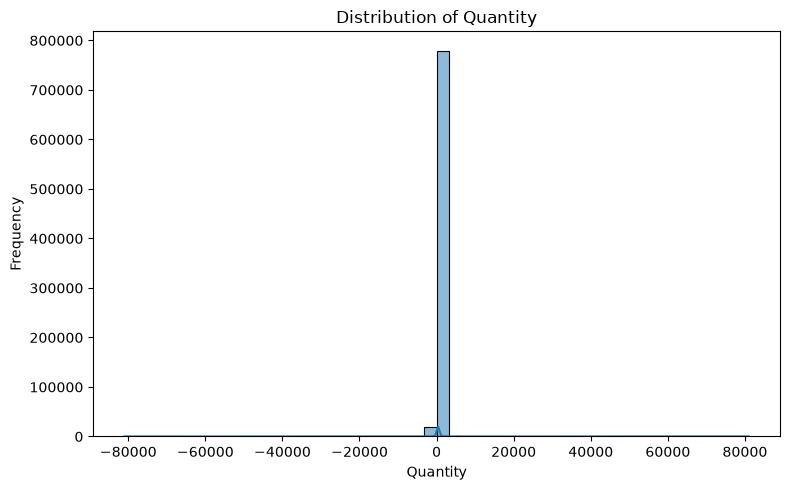

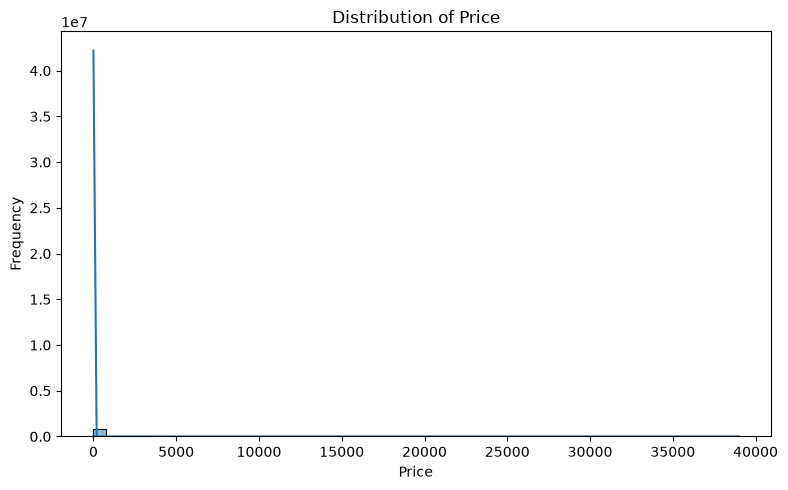

In [24]:
for feature in numerical_features:
    plt.figure(figsize=(8, 5))
    sns.histplot(data=df, x=feature, bins=50, kde=True)
    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

### Observation – Numerical Feature Distributions

The histograms show how transaction quantities and product prices are distributed. The shape of each distribution, including skewness and extreme values, will be examined to understand the purchasing patterns and identify values that may require further investigation during preprocessing.

## Categorical Feature Distributions

The categorical features are examined to understand the variety of countries, products, and stock codes represented in the transactions. Since product descriptions and stock codes can have many unique values, the most frequent categories are visualized for readability.

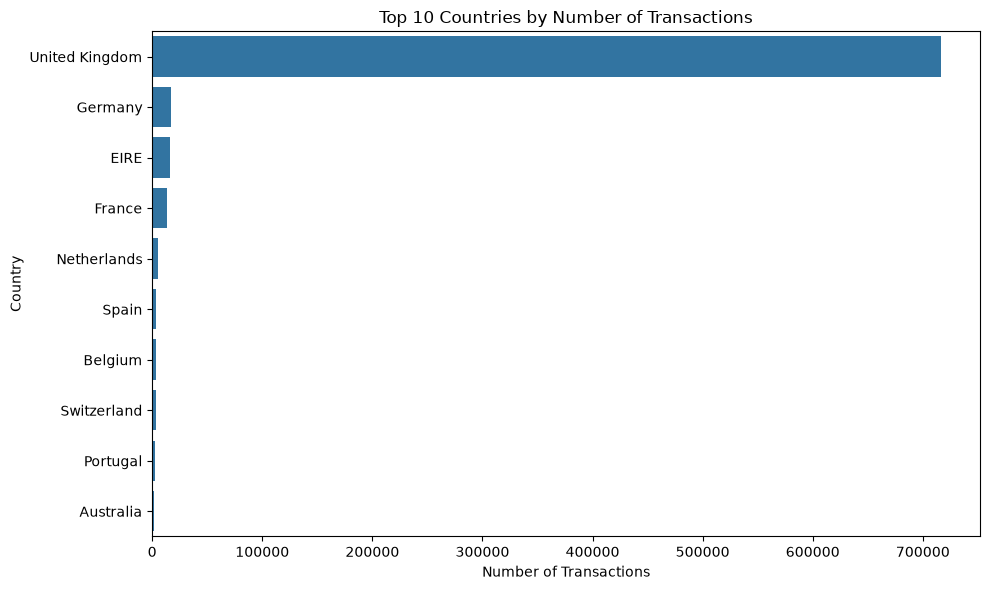

In [25]:
plt.figure(figsize=(10, 6))

country_counts = df["Country"].value_counts().head(10)

sns.barplot(x=country_counts.values, y=country_counts.index)

plt.title("Top 10 Countries by Number of Transactions")
plt.xlabel("Number of Transactions")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

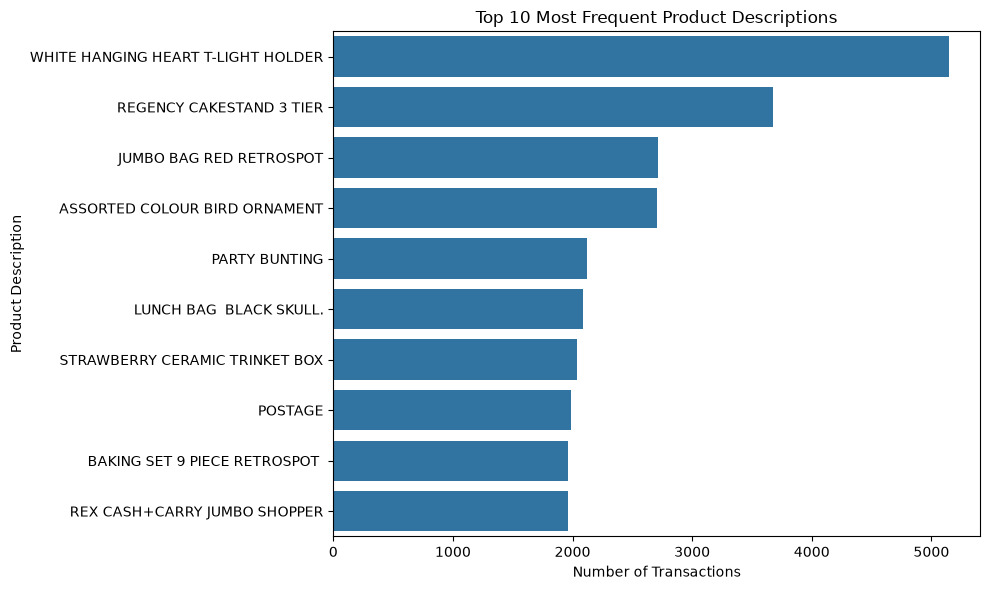

In [26]:
plt.figure(figsize=(10, 6))

description_counts = df["Description"].value_counts().head(10)

sns.barplot(x=description_counts.values, y=description_counts.index)

plt.title("Top 10 Most Frequent Product Descriptions")
plt.xlabel("Number of Transactions")
plt.ylabel("Product Description")
plt.tight_layout()
plt.show()

### Observation – Categorical Feature Distributions

The country distribution highlights the countries contributing the most transactions to the dataset. The product description distribution identifies the most frequently recorded products. These patterns provide an initial understanding of the dataset's transaction composition.

## Transaction Trends Over Time

The invoice date is examined to understand how transaction activity changes over time. Monthly transaction counts can reveal variations in retail activity and provide additional context for understanding customer purchasing behaviour.

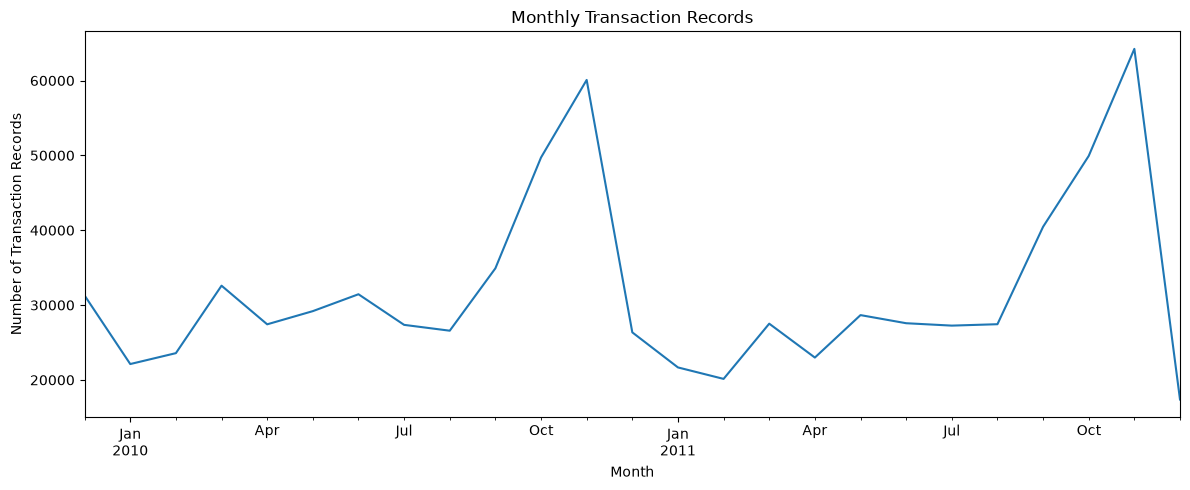

In [27]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

monthly_transactions = (
    df.set_index("InvoiceDate")
      .resample("ME")
      .size()
)

plt.figure(figsize=(12, 5))
monthly_transactions.plot()

plt.title("Monthly Transaction Records")
plt.xlabel("Month")
plt.ylabel("Number of Transaction Records")
plt.tight_layout()
plt.show()

### Observation – Transaction Trends Over Time

The monthly transaction plot illustrates how transaction activity varies across the observed period. Any increases, decreases, or recurring patterns should be described based on the plotted results. These temporal patterns may provide useful context for subsequent customer segmentation.